# The Speed Dating dataset

Data from a speed-dating experiment run at Columbia Business School between 2002 and 2004
([Kaggle](https://www.kaggle.com/datasets/annavictoria/speed-dating-experiment/data)).
Students signed up through a survey, then came to one of 21 events (**waves**). At an event
each person had a four-minute date with every participant of the opposite sex, and after each
date said **yes** or **no** to seeing that person again. A **match** means both said yes.

After cleaning, the graph this project works with has:

| | |
|---|---|
| people (nodes) | **551** (274 women, 277 men) |
| dates (edges) | **4,184** |
| matches | **690**, i.e. 16.5% of dates |

This notebook shows what the raw file looks like and how `prepare_data.py` turns it into that graph.
The last section needs Neo4j running with the data loaded: `docker compose up -d`, then `python prepare_data.py`.

In [1]:
import pandas as pd

from prepare_data import RAW_PATH, build_matches, build_profiles
from speed_dating import HOBBIES, load_pairs, load_people

pd.set_option("display.max_columns", 50)
raw = pd.read_csv(RAW_PATH, encoding="latin-1")

## The raw file

`dataset/Speed Dating Data.csv` has one row **per person per date**, so every date shows up twice,
once from each side. Each row also repeats that person's whole sign-up survey, and adds what they
filled in during and after the event.

In [2]:
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"{raw['iid'].nunique()} participants in {raw['wave'].nunique()} waves")
raw.head()

8,378 rows x 195 columns
551 participants in 21 waves


,iid,id,gender,idg,condtn,wave,round,position,positin1,order,partner,pid,match,int_corr,samerace,age_o,race_o,pf_o_att,pf_o_sin,pf_o_int,pf_o_fun,pf_o_amb,pf_o_sha,dec_o,attr_o,...,fun7_3,amb7_3,shar7_3,attr4_3,sinc4_3,intel4_3,fun4_3,amb4_3,shar4_3,attr2_3,sinc2_3,intel2_3,fun2_3,amb2_3,shar2_3,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
0,1,1.0,0,1,1,1,10,7,NaN,4,1,11.0,0,0.14,0,27.0,2.0,35.0,20.0,20.0,20.0,0.0,5.0,0,6.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
1,1,1.0,0,1,1,1,10,7,NaN,3,2,12.0,0,0.54,0,22.0,2.0,60.0,0.0,0.0,40.0,0.0,0.0,0,7.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
2,1,1.0,0,1,1,1,10,7,NaN,10,3,13.0,1,0.16,1,22.0,4.0,19.0,18.0,19.0,18.0,14.0,12.0,1,10.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
3,1,1.0,0,1,1,1,10,7,NaN,5,4,14.0,1,0.61,0,23.0,2.0,30.0,5.0,15.0,40.0,5.0,5.0,1,7.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
4,1,1.0,0,1,1,1,10,7,NaN,7,5,15.0,1,0.21,0,24.0,3.0,30.0,10.0,20.0,10.0,10.0,20.0,1,8.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN


### Column names and values are codes

Neither the column names nor most of the values explain themselves. To read them you have to
look them up in the codebook, **`dataset/Speed Dating Data Key.doc`**. A few examples:

| column | meaning (from the codebook) |
|---|---|
| `iid` | unique id of the participant |
| `pid` | `iid` of the partner on this date |
| `dec`, `dec_o` | this person's decision and the partner's decision (1 = yes) |
| `match` | 1 when both said yes |
| `gender` | 0 = female, 1 = male |
| `race` | 1 = Black, 2 = European/Caucasian, 3 = Latino, 4 = Asian, 5 = Native American, 6 = other |
| `field_cd` | field of study, 18 codes (1 = law, 5 = engineering, 8 = business, ...) |
| `goal` | why they came, 1 = fun night out ... 4 = serious relationship ... 6 = other |
| `date`, `go_out` | how often they date / go out, **1 = several times a week, 7 = almost never** (lower = more often) |
| `imprace`, `imprelig` | how important a same-race / same-religion partner is, 1-10 |
| `attr1_1` ... `shar1_1` | what they look for in a partner: attractive, sincere, intelligent, fun, ambitious, shared interests |
| `attr3_1` ... `amb3_1` | how they rate themselves on the same attributes, 1-10 |

The attribute columns (`attr1_1`, `amb7_3`, ...) follow one naming pattern, decoded in the next section.

In [3]:
raw[["iid", "pid", "gender", "race", "field_cd", "goal", "date", "go_out", "imprace",
     "attr1_1", "sinc1_1", "attr3_1", "dec", "dec_o", "match"]].head()

,iid,pid,gender,race,field_cd,goal,date,go_out,imprace,attr1_1,sinc1_1,attr3_1,dec,dec_o,match
0,1,11.0,0,4.0,1.0,2.0,7.0,1.0,2.0,15.0,20.0,6.0,1,0,0
1,1,12.0,0,4.0,1.0,2.0,7.0,1.0,2.0,15.0,20.0,6.0,1,0,0
2,1,13.0,0,4.0,1.0,2.0,7.0,1.0,2.0,15.0,20.0,6.0,1,1,1
3,1,14.0,0,4.0,1.0,2.0,7.0,1.0,2.0,15.0,20.0,6.0,1,1,1
4,1,15.0,0,4.0,1.0,2.0,7.0,1.0,2.0,15.0,20.0,6.0,1,1,1


## Reading the attribute columns

More than 100 columns rate the same six attributes, asked in different questions at different
times. Each name reads as **`<attribute><question>_<time>`**. For example, `amb7_3` is question 7
about *ambitious*, asked at time 3.

**Attribute**

| prefix | attribute |
|---|---|
| `attr` | attractive |
| `sinc` | sincere |
| `intel` | intelligent |
| `fun` | fun |
| `amb` | ambitious |
| `shar` | shared interests / hobbies |

**Question**

| number | question | scale |
|---|---|---|
| 1 | What **you** look for in a partner | 100 points to split (waves 6-9: 1-10 each) |
| 2 | What you think the **opposite sex** looks for | 100 points (waves 6-9: 1-10) |
| 3 | How you rate **yourself** | 1-10 |
| 4 | What you think **most of your own sex** look for | 100 points (waves 6-9: 1-10) |
| 5 | How you think **others see you** | 1-10 |
| 7 | Looking back, what **actually** drove your yes/no decisions | 100 points |

There is no question 6. Questions 3 and 5 have no `shar` column, since you can't rate your own
"shared interests".

**Time**

| suffix | when |
|---|---|
| `_1` | sign-up survey, before the event |
| `_s` | halfway through the event, on the scorecard (questions 1 and 3 only) |
| `_2` | the day after the event |
| `_3` | 3-4 weeks after people were sent their matches |

**Columns outside the pattern**

| column | meaning |
|---|---|
| `attr`, `sinc`, ... (no suffix), `like`, `prob` | the rating this person gave **the partner on this date**, 1-10 |
| `attr_o`, `sinc_o`, ..., `dec_o` | the same from the **partner's** side: how the partner rated this person |
| `pf_o_att`, `pf_o_sin`, ... | the partner's answers to question 1 at sign-up (their `attr1_1`, `sinc1_1`, ...) |

**The models only see question 1 and question 3 from time 1 (`pref_*` and `self_*` on the `Person`
nodes). Those are the only attribute answers given before the event.**

### Who answered what

Parsing the column names shows what share of the 551 people answered each question at each time.
Two things make the later columns sparse:

- **People dropped out of the follow-ups.** About 485 answered the day after, and only about 263 answered 3-4 weeks later.
- **Not every wave was asked every question.** Question 4 started in wave 6, question 5 in wave 10,
  and question 7 in wave 10 (3-4 weeks later) or wave 15 (the day after). The halfway scorecard
  was only used in waves 6-11 and 15-20.

Only the sign-up answers to questions 1 and 3 cover nearly everyone, which is another reason the models use just those.

In [4]:
import re

ATTRIBUTE_COLUMN = re.compile(r"^(attr|sinc|intel|fun|amb|shar)(\d)_(\w)$")
QUESTIONS = {
    "1": "1: what I look for", "2": "2: what the opposite sex looks for", "3": "3: how I rate myself",
    "4": "4: what my own sex looks for", "5": "5: how others see me", "7": "7: what actually drove my decisions",
}
TIMES = {"1": "sign-up", "s": "halfway", "2": "day after", "3": "3-4 weeks later"}

per_person = raw.groupby("iid").first()
answered = {}
for col in raw.columns:
    m = ATTRIBUTE_COLUMN.match(col)
    if m:
        attribute, question, time = m.groups()
        # A person answered a question if they gave a value for any of its attributes
        key = (QUESTIONS[question], TIMES[time])
        answered[key] = answered.get(key, False) | per_person[col].notna()

coverage = pd.Series({k: v.sum() for k, v in answered.items()}).unstack()
coverage = coverage.reindex(index=QUESTIONS.values(), columns=TIMES.values())
# Share of all participants who answered
coverage = coverage.fillna(0) / len(per_person)
coverage.style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0, vmax=1)

,sign-up,halfway,day after,3-4 weeks later
1: what I look for,99%,51%,88%,48%
2: what the opposite sex looks for,99%,0%,67%,35%
3: how I rate myself,98%,50%,88%,48%
4: what my own sex looks for,76%,0%,67%,35%
5: how others see me,57%,0%,50%,24%
7: what actually drove my decisions,0%,0%,23%,24%


### Which waves were asked each question

The same table split by wave. Each cell is the share of that wave's participants who answered,
so 0% means the wave was never asked that question.

In [5]:
waves = per_person["wave"]
rows = {}
for (question, time), has in answered.items():
    # Share of that wave's own participants who answered
    rows[(question, time)] = has.groupby(waves).mean()
by_wave = pd.DataFrame(rows).T.reindex(
    [(q, t) for q in QUESTIONS.values() for t in TIMES.values() if (q, t) in rows])
by_wave.style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0, vmax=1)

## From raw file to graph

`prepare_data.py` turns these 8,378 rows into a graph: one `Person` node per participant, and one
`MATCH` or `NO_MATCH` relationship per date. The steps are below, each with a short check on the data.

### 1. Only the sign-up survey is kept

The survey everyone filled in *before* the event goes on the `Person` nodes. Everything recorded
during or after a date is dropped: the ratings people gave each other (`attr`, `like`, ...), the
decisions (`dec`, `dec_o`), and the follow-up surveys (`*_2`, `*_3`). Those answers depend on how
the date went, so keeping them would give the outcome away to the model. Out of 195 columns, 40 are kept.

In [6]:
from prepare_data import RAW_PROFILE_COLUMNS

print(len(RAW_PROFILE_COLUMNS), "of", raw.shape[1], "columns kept:")
print(", ".join(RAW_PROFILE_COLUMNS))

40 of 195 columns kept:
iid, wave, gender, age, field_cd, goal, race, date, go_out, imprace, imprelig, exphappy, sports, tvsports, exercise, dining, museums, art, hiking, gaming, clubbing, reading, tv, theater, movies, concerts, music, shopping, yoga, attr1_1, sinc1_1, intel1_1, fun1_1, amb1_1, shar1_1, attr3_1, sinc3_1, intel3_1, fun3_1, amb3_1


### 2. One row per person

Below are all 195 columns for person 1, one row for each of their 10 dates. Scroll right to see
that the columns about the date itself change from row to row (`pid`, `match`, `dec`, the ratings),
while the sign-up survey answers (`age`, `race`, `goal`, `attr1_1`, the hobbies, ...) repeat on every
row. Grouping by `iid` keeps those survey answers once, giving one profile per person: 551 profiles.

In [7]:
# Every column for person 1: all 10 of their dates (wave 1 had 10 men)
with pd.option_context("display.max_columns", None):
    display(raw.loc[raw["iid"] == 1].head(10))

,iid,id,gender,idg,condtn,wave,round,position,positin1,order,partner,pid,match,int_corr,samerace,age_o,race_o,pf_o_att,pf_o_sin,pf_o_int,pf_o_fun,pf_o_amb,pf_o_sha,dec_o,attr_o,sinc_o,intel_o,fun_o,amb_o,shar_o,like_o,prob_o,met_o,age,field,field_cd,undergra,mn_sat,tuition,race,imprace,imprelig,from,zipcode,income,goal,date,go_out,career,career_c,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,exphappy,expnum,attr1_1,sinc1_1,intel1_1,fun1_1,amb1_1,shar1_1,attr4_1,sinc4_1,intel4_1,fun4_1,amb4_1,shar4_1,attr2_1,sinc2_1,intel2_1,fun2_1,amb2_1,shar2_1,attr3_1,sinc3_1,fun3_1,intel3_1,amb3_1,attr5_1,sinc5_1,intel5_1,fun5_1,amb5_1,dec,attr,sinc,intel,fun,amb,shar,like,prob,met,match_es,attr1_s,sinc1_s,intel1_s,fun1_s,amb1_s,shar1_s,attr3_s,sinc3_s,intel3_s,fun3_s,amb3_s,satis_2,length,numdat_2,attr7_2,sinc7_2,intel7_2,fun7_2,amb7_2,shar7_2,attr1_2,sinc1_2,intel1_2,fun1_2,amb1_2,shar1_2,attr4_2,sinc4_2,intel4_2,fun4_2,amb4_2,shar4_2,attr2_2,sinc2_2,intel2_2,fun2_2,amb2_2,shar2_2,attr3_2,sinc3_2,intel3_2,fun3_2,amb3_2,attr5_2,sinc5_2,intel5_2,fun5_2,amb5_2,you_call,them_cal,date_3,numdat_3,num_in_3,attr1_3,sinc1_3,intel1_3,fun1_3,amb1_3,shar1_3,attr7_3,sinc7_3,intel7_3,fun7_3,amb7_3,shar7_3,attr4_3,sinc4_3,intel4_3,fun4_3,amb4_3,shar4_3,attr2_3,sinc2_3,intel2_3,fun2_3,amb2_3,shar2_3,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
0,1,1.0,0,1,1,1,10,7,NaN,4,1,11.0,0,0.14,0,27.0,2.0,35.00,20.00,20.00,20.00,0.00,5.00,0,6.0,8.0,8.0,8.0,8.0,6.0,7.0,4.0,2.0,21.0,Law,1.0,NaN,NaN,NaN,4.0,2.0,4.0,Chicago,"60,521","69,487.00",2.0,7.0,1.0,lawyer,NaN,9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,3.0,2.0,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,35.0,20.0,15.0,20.0,5.0,5.0,6.0,8.0,8.0,8.0,7.0,NaN,NaN,NaN,NaN,NaN,1,6.0,9.0,7.0,7.0,6.0,5.0,7.0,6.0,2.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,19.44,16.67,13.89,22.22,11.11,16.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,7.0,8.0,7.0,6.0,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.0,NaN,NaN,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
1,1,1.0,0,1,1,1,10,7,NaN,3,2,12.0,0,0.54,0,22.0,2.0,60.00,0.00,0.00,40.00,0.00,0.00,0,7.0,8.0,10.0,7.0,7.0,5.0,8.0,4.0,2.0,21.0,Law,1.0,NaN,NaN,NaN,4.0,2.0,4.0,Chicago,"60,521","69,487.00",2.0,7.0,1.0,lawyer,NaN,9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,3.0,2.0,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,35.0,20.0,15.0,20.0,5.0,5.0,6.0,8.0,8.0,8.0,7.0,NaN,NaN,NaN,NaN,NaN,1,7.0,8.0,7.0,8.0,5.0,6.0,7.0,5.0,1.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,19.44,16.67,13.89,22.22,11.11,16.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,7.0,8.0,7.0,6.0,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.0,NaN,NaN,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
2,1,1.0,0,1,1,1,10,7,NaN,10,3,13.0,1,0.16,1,22.0,4.0,19.00,18.00,19.00,18.00,14.00,12.00,1,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,1.0,21.0,Law,1.0,NaN,NaN,NaN,4.0,2.0,4.0,Chicago,"60,521","69,487.00",2.0,7.0,1.0,lawyer,NaN,9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,3.0,2.0,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,35.0,20.0,15.0,20.0,5.0,5.0,6.0,8.0,8.0,8.0,7.0,NaN,NaN,NaN,NaN,NaN,1,5.0,8.0,9.0,8.0,5.0,7.0,7.0,NaN,1.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,19.44,16.67,13.89,22.22,11.11,16.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,7.0,8.0,7.0,6.0,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.0,NaN,NaN,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
3,1,1.0,0,1,1,1,10,7,NaN,5,4,14.0,1,0.61,0,23.0,2.0,30.00,5.00,15.00,40.00,5.00,

### 3. One row per date

Each date is in the file twice: once in person A's rows and once in person B's. Below is the
same date seen from both sides. Person 1 said yes and person 11 said no, so on both rows
`match` = 0. Keeping only the rows where `iid < pid` leaves each date once.

Ten rows have no partner id (`pid`). All of them are from wave 5, from dates with the woman
who had partner number 7 that night, and she is missing from the file. These rows are dropped.

In [8]:
cols = ["iid", "pid", "dec", "dec_o", "match"]
display(raw.loc[((raw["iid"] == 1) & (raw["pid"] == 11)) | ((raw["iid"] == 11) & (raw["pid"] == 1)), cols])

print(f"rows without a partner id: {raw['pid'].isna().sum()}")
with_partner = raw.dropna(subset=["pid"])
print(f"{len(with_partner):,} rows with a partner -> {(with_partner['iid'] < with_partner['pid']).sum():,} dates")

,iid,pid,dec,dec_o,match
0,1,11.0,1,0,0
100,11,1.0,0,1,0


rows without a partner id: 10
8,368 rows with a partner -> 4,184 dates


### 4. Hobby scores are clipped to 0-10

The 17 hobby questions ask for interest on a 1-10 scale, but a few answers are above 10.

In [9]:
hobbies = raw.groupby("iid")[HOBBIES].first()
over = (hobbies > 10).sum()
over[over > 0].rename("people with an answer above 10")

gaming     5
reading    3
Name: people with an answer above 10, dtype: int64

### 5. Preferences become shares that add up to 1

The six "what do you look for" answers (`attr1_1` ... `shar1_1`) come from a 100-point split:
the codebook says waves 1-5 and 10-21 were told to give out 100 points, while waves 6-9 rated
each attribute 1-10. In this Kaggle file waves 6-9 are **already rescaled to 100 points**, but
not every total is exactly 100 (some are between 90 and 148). Dividing each answer by the
person's own total turns all of them into shares that add up to 1, so people stay comparable.

In [10]:
prefs = ["attr1_1", "sinc1_1", "intel1_1", "fun1_1", "amb1_1", "shar1_1"]
totals = raw.groupby("iid")[prefs].first().sum(axis=1, min_count=1)
totals.round().value_counts().sort_index().rename("people").to_frame().T

,90.0,95.0,100.0,101.0,110.0,120.0,148.0
people,4,1,534,1,1,2,1


### 6. Codes become labels

Coded answers are mapped to readable values (gender `0` -> `female`, `field_cd` `5` -> `engineering`,
and the same for `goal` and `race`), and the columns get readable names (`imprace` ->
`importance_same_race`, `attr1_1` -> `pref_attractive`, `attr3_1` -> `self_attractive`, ...).
The result is the table that goes on the `Person` nodes:

In [11]:
people_raw = build_profiles(raw.dropna(subset=["pid"]))
people_raw.head()

,id,wave,gender,age,field,goal,race,date_frequency,go_out_frequency,importance_same_race,importance_same_religion,expected_happiness,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,pref_attractive,pref_sincere,pref_intelligent,pref_fun,pref_ambitious,pref_shared_interests,self_attractive,self_sincere,self_intelligent,self_fun,self_ambitious
0,1,1,female,21.0,law,meet new people,asian,7.0,1.0,2.0,4.0,3.0,9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,0.15,0.20,0.20,0.15,0.15,0.15,6.0,8.0,8.0,8.0,7.0
1,2,1,female,24.0,law,fun night out,white,5.0,1.0,2.0,5.0,4.0,3.0,2.0,7.0,10.0,8.0,6.0,3.0,5.0,8.0,10.0,1.0,9.0,8.0,7.0,8.0,3.0,1.0,0.45,0.05,0.25,0.20,0.00,0.05,7.0,5.0,8.0,10.0,3.0
2,3,1,female,25.0,math,other,white,3.0,1.0,8.0,4.0,4.0,3.0,8.0,7.0,8.0,5.0,5.0,8.0,4.0,5.0,7.0,8.0,7.0,7.0,7.0,5.0,8.0,7.0,0.35,0.10,0.35,0.10,0.10,0.00,8.0,9.0,9.0,8.0,8.0
3,4,1,female,23.0,law,fun night out,white,5.0,1.0,1.0,1.0,1.0,1.0,1.0,6.0,7.0,6.0,7.0,7.0,5.0,7.0,7.0,7.0,9.0,7.0,8.0,7.0,1.0,8.0,0.20,0.20,0.20,0.20,0.10,0.10,7.0,8.0,7.0,9.0,8.0
4,5,1,female,21.0,law,meet new people,white,4.0,1.0,8.0,1.0,7.0,7.0,4.0,7.0,7.0,6.0,8.0,6.0,6.0,8.0,6.0,8.0,6.0,6.0,3.0,7.0,8.0,3.0,0.20,0.05,0.25,0.25,0.10,0.15,6.0,3.0,10.0,6.0,8.0


## What ends up in Neo4j

Reading the graph back from Neo4j (as the models do) gives the numbers from the top of the notebook.

In [12]:
people, pairs = load_people(), load_pairs()
print(f"{len(people)} people ({people['gender'].value_counts().to_dict()})")
print(f"{len(pairs):,} dates, {pairs['match'].sum()} matches ({pairs['match'].mean():.1%} of dates)")
pairs.head()

551 people ({'male': 277, 'female': 274})
4,184 dates, 690 matches (16.5% of dates)


,person_a,person_b,match
0,1,11,0
1,1,12,0
2,1,13,1
3,1,14,1
4,1,15,1


## Missing values

Gaps show up at three stages: the raw file, the cleaned profiles in Neo4j, and the step in
`train.py` that fills them in before training.

### In the raw file

About a quarter of all cells are empty. Almost all of the gaps are in the follow-up surveys
(`*_2`, `*_3`) and in questions only some waves were asked (see "Who answered what" above).
`prepare_data.py` drops those columns anyway, since they come from after the event.

In [13]:
share_missing = raw.isna().mean()
print(f"{raw.isna().to_numpy().mean():.1%} of all cells are empty")
print(f"{(share_missing == 0).sum()} of {raw.shape[1]} columns are complete, "
      f"{(share_missing > 0.5).sum()} are more than half empty")
share_missing.sort_values(ascending=False).head(10).rename("empty").to_frame().T.style.format("{:.0%}")

26.4% of all cells are empty
13 of 195 columns are complete, 59 are more than half empty


,num_in_3,numdat_3,expnum,sinc7_2,amb7_2,shar7_2,fun7_2,attr7_2,intel7_2,attr5_3
empty,92%,82%,79%,77%,77%,76%,76%,76%,76%,76%


### In the profiles

After cleaning, gaps are rare, and they sit in a few people rather than being spread out:
536 of 551 people answered everything, 8 skipped a few questions, and 7 have almost nothing.

Neo4j doesn't store a property for a blank answer. `load_people()` brings those columns back as
NaN, so the counts below are what the model receives. The dates themselves (`pairs`) have no gaps.

In [14]:
answers = people.drop(columns=["id", "wave", "gender"])  # these three are never missing
missing_per_person = answers.isna().sum(axis=1)
print(f"dates with a missing value: {pairs.isna().any(axis=1).sum()}")

bands = pd.cut(missing_per_person, [-1, 0, 5, answers.shape[1]],
               labels=["none", "1-5", f"more than 5 (of {answers.shape[1]})"])
bands.value_counts().sort_index().rename_axis("missing answers").rename("people").to_frame().T

dates with a missing value: 0


missing answers,none,1-5,more than 5 (of 37)
people,536,8,7


In [15]:
missing_per_column = answers.isna().sum()
missing_per_column[missing_per_column > 0].sort_values(ascending=False).rename("people missing it").to_frame().T

,pref_shared_interests,self_fun,self_attractive,self_ambitious,self_sincere,pref_ambitious,self_intelligent,pref_fun,date_frequency,age,expected_happiness,field,goal,theater,go_out_frequency,importance_same_race,importance_same_religion,sports,tvsports,exercise,dining,pref_intelligent,tv,reading,clubbing,gaming,hiking,art,museums,shopping,pref_sincere,pref_attractive,yoga,concerts,music,movies,race
people missing it,10,9,9,9,9,9,9,8,8,8,8,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,6


**The 7 nearly empty profiles.** Apart from id, wave and gender they have practically no
survey answers, so they most likely never filled in the sign-up survey. They are still in the graph
and went on dates like everyone else:

In [16]:
empty = people.loc[missing_per_person > 5, ["id", "wave", "gender"]].copy()
on_date = lambda pid: (pairs["person_a"] == pid) | (pairs["person_b"] == pid)
empty["missing answers"] = missing_per_person[empty.index]
empty["dates"] = [on_date(pid).sum() for pid in empty["id"]]
empty["matches"] = [pairs.loc[on_date(pid), "match"].sum() for pid in empty["id"]]
empty

,id,wave,gender,missing answers,dates,matches
27,28,2,female,34,16,1
57,58,3,female,37,10,2
58,59,3,female,37,10,0
134,136,6,female,37,5,1
337,339,13,male,37,10,4
338,340,13,male,37,10,1
344,346,14,female,37,18,6


### How training fills the gaps

`build_node_features` in `train.py` handles them before standardising:

- **Numeric columns** (age, hobbies, preferences, self-ratings, ...): a missing value becomes the
  column's **median**.
- **Categorical columns** (`goal`, `field`, `race`): a missing value becomes an **all-zero one-hot
  block**, i.e. "no category". `gender` is never missing.

What follows from that:

- **The nearly empty people all look like the same average person.** Their numeric features are
  all medians, so they are identical, as the table below shows. The model can only tell them apart
  through their matches in the graph.
- **The model can't tell a filled-in value from a real one.** There is no "was missing" flag. With
  15 incomplete people out of 551 that's acceptable, and a missing-value indicator would be an easy
  addition.
- **Some preference shares add up to slightly more than 1.** If one preference answer is missing,
  the others are divided by their own total (so they already add up to 1), and the missing one then
  gets the median on top. This affects 3 people.
- **The medians come from all 551 people**, including the validation and test people. It's a small
  leak, of survey features only and never of match labels.

In [17]:
from train import NUMERIC, build_node_features

x = build_node_features(people)
# Rows of x follow the row order of `people`; first numeric features, already standardised
features = pd.DataFrame(x[empty.index.to_numpy(), :6].numpy(), columns=NUMERIC[:6], index=empty["id"])
features.round(3)

,age,date_frequency,go_out_frequency,importance_same_race,importance_same_religion,expected_happiness
id,,,,,,
28,-0.095,0.011,-0.13,-0.258,-0.209,0.278
58,-0.095,0.011,-0.13,-0.258,-0.209,0.278
59,-0.095,0.011,-0.13,-0.258,-0.209,0.278
136,-0.095,0.011,-0.13,-0.258,-0.209,0.278
339,-0.095,0.011,-0.13,-0.258,-0.209,0.278
340,-0.095,0.011,-0.13,-0.258,-0.209,0.278
346,-0.095,0.011,-0.13,-0.258,-0.209,0.278


## Visualizations

The real match network, drawn from the cleaned graph loaded from Neo4j above.

In [18]:
%matplotlib inline
# Re-read project .py files (plot_style, speed_dating, ...) when they change, without a kernel restart
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from matplotlib.lines import Line2D

from plot_style import (
    BLUE, GENDER_COLORS, INK_2, MATCH_COLOR, MATCH_LINE, MUTED, NO_MATCH_COLOR, SURFACE,
    gender_legend, match_graph, network_layout, no_axes,
)
# people and pairs are already loaded from Neo4j in "What ends up in Neo4j"

### Match network

Each line is a match (both people said yes). Each cluster is one speed-dating event:
people only dated others at the same event.

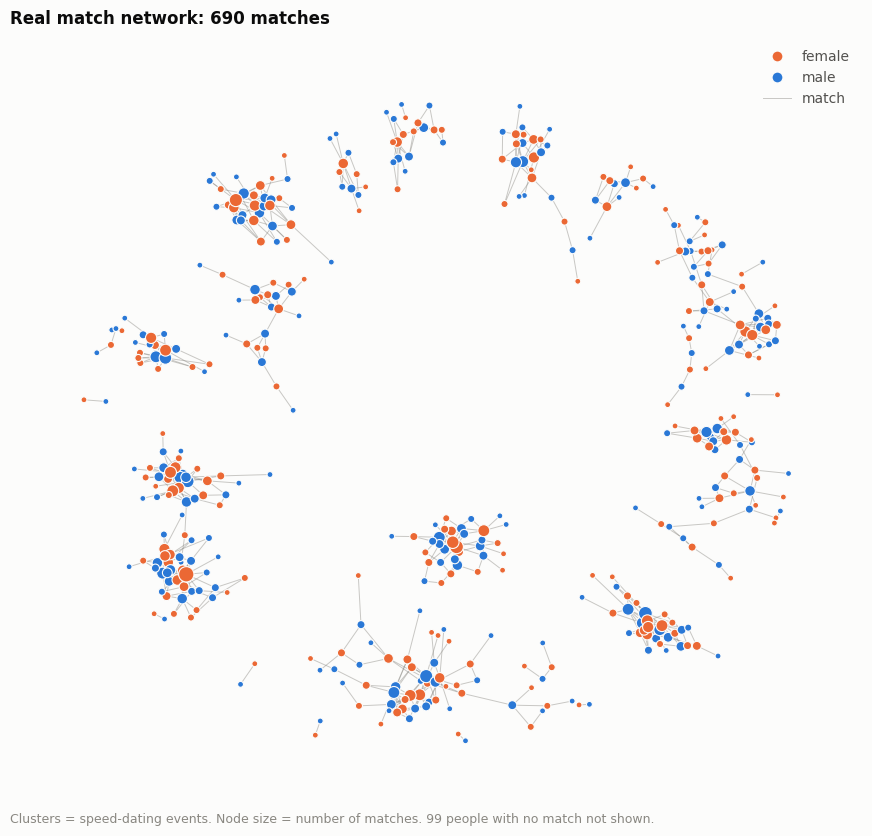

In [19]:
graph = match_graph(people, pairs)
pos = network_layout(graph)
nodes = list(graph.nodes)

fig, ax = plt.subplots(figsize=(11, 10))
nx.draw_networkx_edges(graph, pos, ax=ax, edge_color=MATCH_LINE["color"],
                       width=MATCH_LINE["linewidth"], alpha=MATCH_LINE["alpha"])
nx.draw_networkx_nodes(graph, pos, nodelist=nodes, ax=ax,
                       node_color=[GENDER_COLORS[graph.nodes[n]["gender"]] for n in nodes],
                       node_size=[10 + 8 * graph.degree(n) for n in nodes],
                       edgecolors=SURFACE, linewidths=0.8)
no_axes(ax)
n_alone = len(people) - graph.number_of_nodes()
ax.set_title(f"Real match network: {graph.number_of_edges()} matches")
ax.text(0, -0.02, f"Clusters = speed-dating events. Node size = number of matches. "
        f"{n_alone} people with no match not shown.", transform=ax.transAxes, color=MUTED, fontsize=9)
gender_legend(ax)

### Every date: match or not

All 4,184 dates, one panel per event. People sit on a circle, women on the left half and men
on the right, so every line across the circle is one date. Green = match (both said yes),
red = no match. Matches are drawn on top so they stay visible among the red lines.

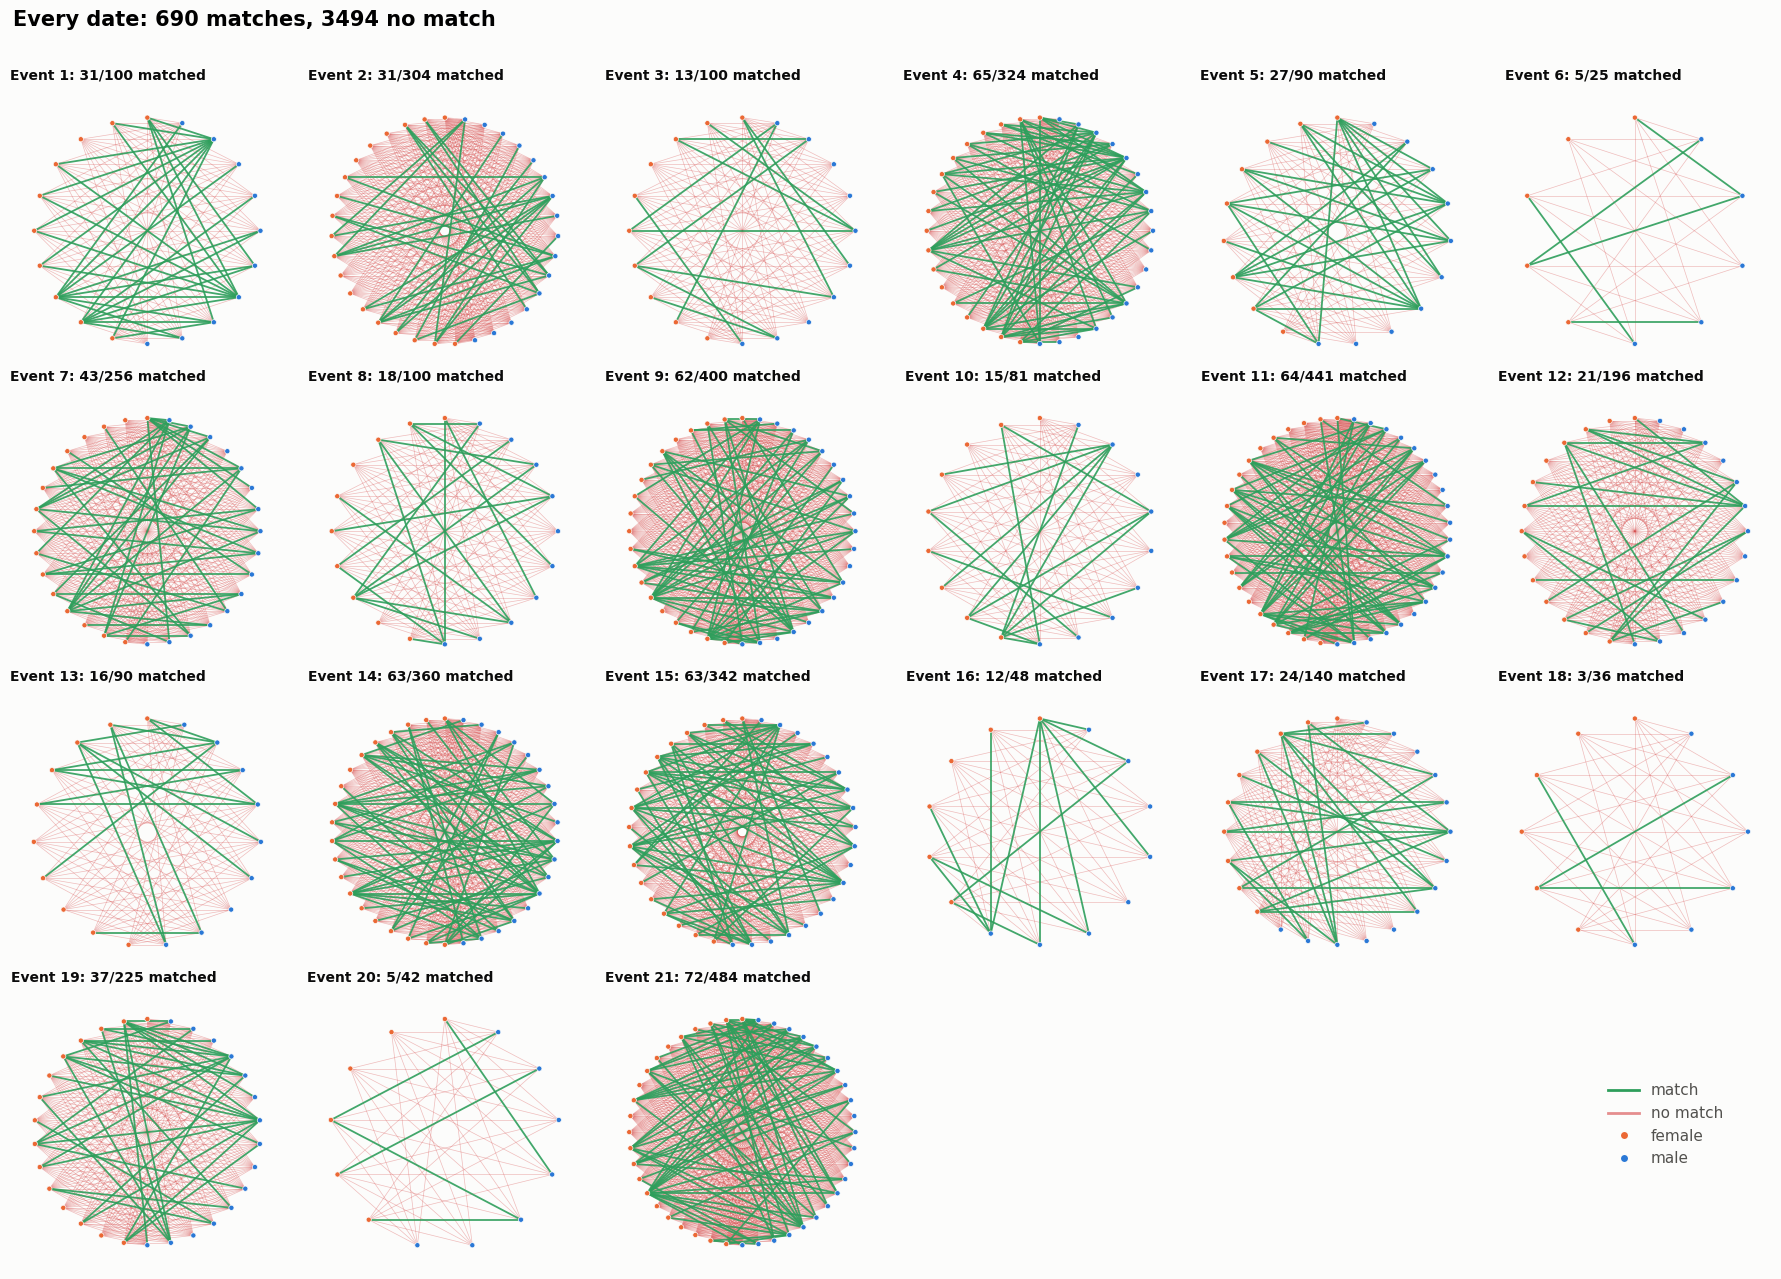

In [20]:
wave_of = people.set_index("id")["wave"]
pairs["wave"] = pairs["person_a"].map(wave_of)  # both people on a date are from the same event
waves = sorted(people["wave"].unique())

fig, axes = plt.subplots(4, 6, figsize=(18, 13))
for ax, wave in zip(axes.flat, waves):
    here = people[people["wave"] == wave].sort_values(["gender", "id"])  # female first: left half
    dates = pairs[pairs["wave"] == wave]
    graph = nx.Graph()
    graph.add_nodes_from(here["id"])
    graph.add_edges_from(dates[["person_a", "person_b"]].itertuples(index=False))
    # Start at the top and go anticlockwise, so women fill the left half and men the right
    angles = np.pi / 2 + 2 * np.pi * np.arange(len(here)) / len(here)
    pos = {pid: (np.cos(a), np.sin(a)) for pid, a in zip(here["id"], angles)}

    for outcome, color, width, alpha in ((0, NO_MATCH_COLOR, 0.5, 0.35), (1, MATCH_COLOR, 1.3, 0.9)):
        edges = dates.loc[dates["match"] == outcome, ["person_a", "person_b"]].itertuples(index=False)
        nx.draw_networkx_edges(graph, pos, edgelist=list(edges), ax=ax, edge_color=color, width=width, alpha=alpha)
    nx.draw_networkx_nodes(graph, pos, ax=ax, node_size=14, edgecolors=SURFACE, linewidths=0.5,
                           node_color=[GENDER_COLORS[g] for g in here["gender"]])
    no_axes(ax)
    ax.set_aspect("equal")
    ax.set_title(f"Event {wave}: {dates['match'].sum()}/{len(dates)} matched", fontsize=10)
for ax in axes.flat[len(waves):]:
    ax.set_visible(False)

fig.legend(handles=[Line2D([], [], color=MATCH_COLOR, linewidth=2, label="match"),
                    Line2D([], [], color=NO_MATCH_COLOR, linewidth=2, alpha=0.6, label="no match"),
                    Line2D([], [], marker="o", linestyle="", markerfacecolor=GENDER_COLORS["female"],
                           markeredgecolor=SURFACE, label="female"),
                    Line2D([], [], marker="o", linestyle="", markerfacecolor=GENDER_COLORS["male"],
                           markeredgecolor=SURFACE, label="male")],
           loc="lower right", bbox_to_anchor=(0.97, 0.08), fontsize=11)
fig.suptitle(f"Every date: {pairs['match'].sum()} matches, {(pairs['match'] == 0).sum()} no match",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))

### Survey answers: women vs men

The charts below compare how women and men answered the sign-up survey. Each bar is the share of
**that gender** who gave the answer, so the bars of one colour add up to 100%. People who skipped
the question are left out, and the legend shows how many of each gender answered.

In [21]:
from matplotlib.ticker import MaxNLocator, PercentFormatter

from speed_dating import GENDERS, PREFERENCE_NAMES, PREFERENCES, SELF_RATINGS

BAR = 0.36  # bar thickness, in category slots
GAP = 0.03  # surface gap between neighbouring bars of one category


def titled(ax, title, subtitle=""):
    ax.set_title(title, pad=24 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=MUTED, fontsize=9)


def capitalised(labels):
    return [label[0].upper() + label[1:] for label in labels]


def hbars(ax, categories, series, fmt="{:.0%}", percent=True, invert=True):
    """Horizontal bars, one group per category. series = [(label, values, color), ...].

    Only each series' largest bar gets a value label; the x axis carries the rest.
    """
    y = np.arange(len(categories))
    offsets = (np.arange(len(series)) - (len(series) - 1) / 2) * (BAR + GAP)
    for offset, (label, values, color) in zip(offsets, series):
        values = np.asarray(values, dtype=float)
        bars = ax.barh(y + offset, values, height=BAR, color=color, label=label)
        top = np.nanargmax(values)
        ax.bar_label(bars, labels=[fmt.format(v) if i == top else "" for i, v in enumerate(values)],
                     padding=4, color=INK_2, fontsize=9)
    ax.set_yticks(y, capitalised(categories))
    if invert:  # first category at the top; axes sharing y must be inverted only once
        ax.invert_yaxis()
    ax.set_xlim(0, max(np.nanmax(np.asarray(v, dtype=float)) for _, v, _ in series) * 1.15)
    if percent:
        ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)  # gridlines behind the bars
    ax.tick_params(axis="y", length=0, labelcolor=INK_2)


def plot_by_gender(table, title, subtitle="", xlabel="", fmt="{:.0%}", percent=True, legend=None):
    """One female and one male bar per row of `table` (columns "female" and "male")."""
    legend = legend or {}
    fig, ax = plt.subplots(figsize=(9, 0.62 * len(table) + 1.4))
    hbars(ax, list(table.index), [(legend.get(g, g), table[g], GENDER_COLORS[g]) for g in ("female", "male")],
          fmt=fmt, percent=percent)
    ax.set_xlabel(xlabel)
    titled(ax, title, subtitle)
    ax.legend(loc="lower right")
    fig.tight_layout()
    plt.show()


def answer_shares(column, order, frame=None):
    """Share of women and of men giving each answer, in `order`. Skipped answers are left out."""
    answered = (people if frame is None else frame).dropna(subset=[column])
    shares = (answered.groupby("gender")[column].value_counts(normalize=True)
              .unstack("gender").reindex(order).fillna(0))
    return shares[["female", "male"]], answered["gender"].value_counts()


def plot_answer_shares(column, order, title, subtitle="", frame=None):
    """Bars per answer of a categorical survey question, female and male side by side."""
    shares, counts = answer_shares(column, order, frame)
    plot_by_gender(shares, title, subtitle, xlabel="share of that gender",
                   legend={g: f"{g} ({counts[g]} answered)" for g in ("female", "male")})


def gender_histograms(values, bins, title, subtitle="", xlabel="", median_fmt="{:.0f}", percent_x=False):
    """One histogram panel per gender (shares of that gender), same axes; the line marks the median."""
    fig, axes = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, sharey=True)
    for ax, gender in zip(axes, ("female", "male")):
        v = values[gender].dropna()
        ax.hist(v, bins=bins, weights=np.full(len(v), 1 / len(v)), color=GENDER_COLORS[gender], rwidth=0.85)
        ax.axvline(v.median(), color=INK_2, linewidth=1)
        ax.set_title(f"{capitalised([gender])[0]} ({len(v)} people), median {median_fmt.format(v.median())}",
                     fontsize=10, pad=4)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))  # whole-percent ticks
        ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.grid(axis="x", visible=False)
        ax.set_axisbelow(True)
    if percent_x:
        axes[1].xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    axes[1].set_xlabel(xlabel)
    fig.suptitle(title, x=0.012, ha="left", fontsize=12, fontweight="bold")
    if subtitle:
        fig.text(0.012, 0.925, subtitle, color=MUTED, fontsize=9)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()


def fold_rare(answers, min_people=10, other="other"):
    """Fold answers given by fewer than `min_people` into `other`.

    Returns the folded answers and their order: most common first, `other` last.
    """
    counts = answers.value_counts()
    folded = answers.where(~answers.isin(counts[counts < min_people].index) | answers.isna(), other)
    order = [a for a in folded.value_counts().index if a != other]
    return folded, order + ([other] if (folded == other).any() else [])

#### Why did they come?

The codebook question: *"What is your primary goal in participating in this event?"*, answered at
sign-up. The six answers are *seemed like a fun night out*, *to meet new people*, *to get a date*,
*looking for a serious relationship*, *to say I did it* and *other*.

Most people of both genders came for a fun night out (about 42%) or to meet new people (32-37%).
Few came looking for a date (5% of women, 10% of men) or a serious relationship (3% and 5%).
Women lean slightly more towards meeting new people, and men are about twice as likely to say
they came to get a date. 7 people (5 women, 2 men) didn't answer.

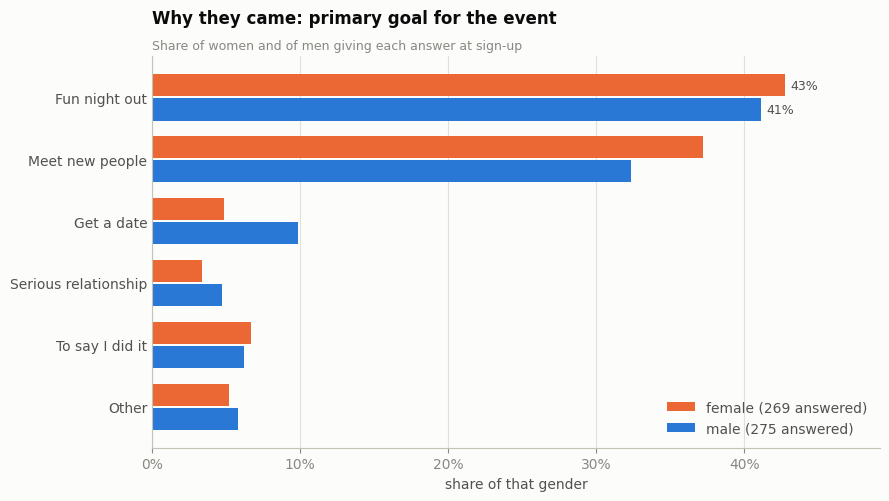

In [22]:
from speed_dating import GOALS

plot_answer_shares("goal", GOALS.values(), "Why they came: primary goal for the event",
                   "Share of women and of men giving each answer at sign-up")

#### What they study

`field` is the field of study, coded into 18 groups in the codebook (`field_cd`). Almost everyone
was a Columbia graduate student, so this is mostly which school they were in. Fields with fewer
than 10 people are folded into *other*.

The two genders study very different things. Over a third of the men are in **business / economics
/ finance** (36%), and another 16% in engineering. Women are spread much more evenly: social
science / psychology, education, biology / chemistry / physics, business and social work each have
11-13%. Education and social work are almost entirely women.

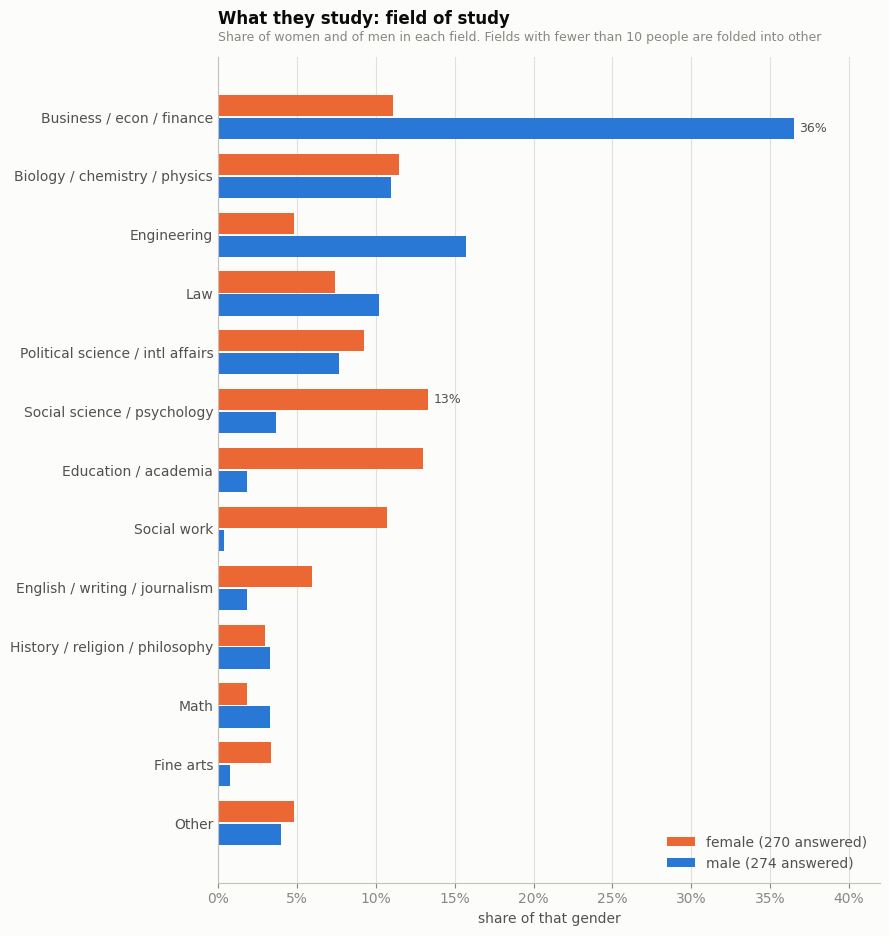

In [23]:
studies = people.assign(field=fold_rare(people["field"])[0])
plot_answer_shares("field", fold_rare(people["field"])[1], "What they study: field of study",
                   "Share of women and of men in each field. Fields with fewer than 10 people are folded into other",
                   frame=studies)

#### What they want to work as

`career_c` is the intended career, coded into 17 groups in the codebook. It isn't on the `Person`
nodes (the model doesn't use it), so it comes from the raw file. Careers with fewer than 10 people
are folded into *other*.

Careers follow the fields: **business / finance / consulting** is the top plan for men (38%),
**academic / research** for women (32%, also second for men at 24%). Women are more likely to aim
for psychology, social work and international / humanitarian work.

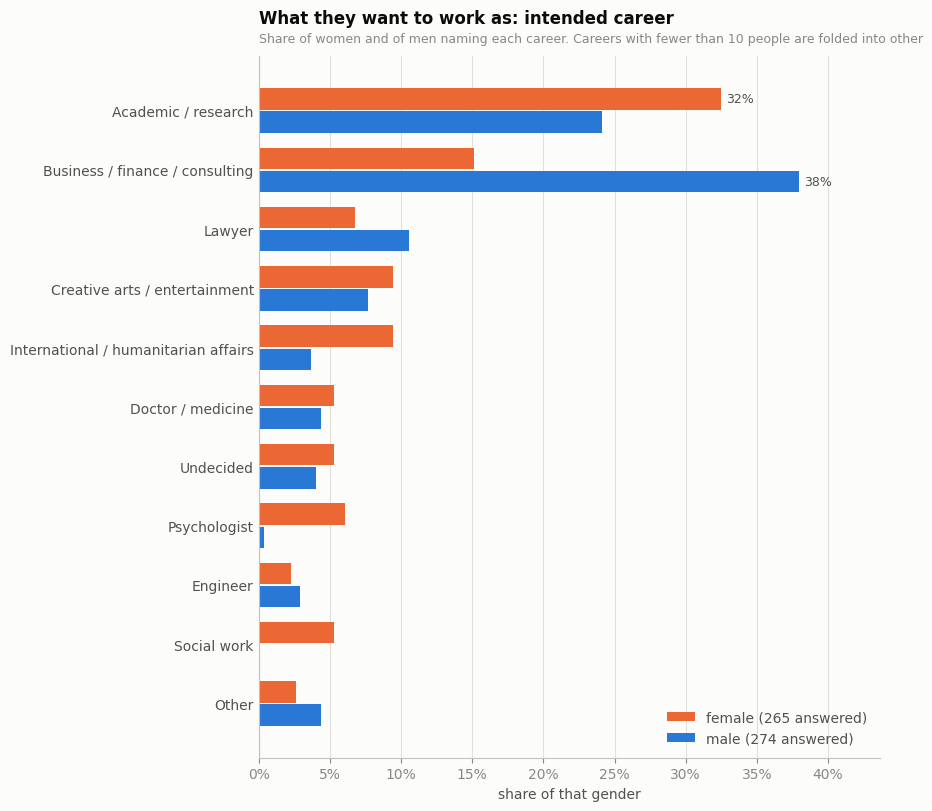

In [24]:
# Career codes from the codebook (career_c)
CAREERS = {
    1: "lawyer", 2: "academic / research", 3: "psychologist", 4: "doctor / medicine", 5: "engineer",
    6: "creative arts / entertainment", 7: "business / finance / consulting", 8: "real estate",
    9: "international / humanitarian affairs", 10: "undecided", 11: "social work", 12: "speech pathology",
    13: "politics", 14: "pro sports / athletics", 15: "other", 16: "journalism", 17: "architecture",
}
careers, career_order = fold_rare(per_person["career_c"].map(CAREERS))
plot_answer_shares("career", career_order, "What they want to work as: intended career",
                   "Share of women and of men naming each career. Careers with fewer than 10 people are folded into other",
                   frame=pd.DataFrame({"gender": per_person["gender"].map(GENDERS), "career": careers}))

#### Age

Participants were mostly graduate students: 87% are between 21 and 30. Men are a little older
on average (median 27 vs 26), and the oldest participants are a 55-year-old woman and a
42-year-old man.

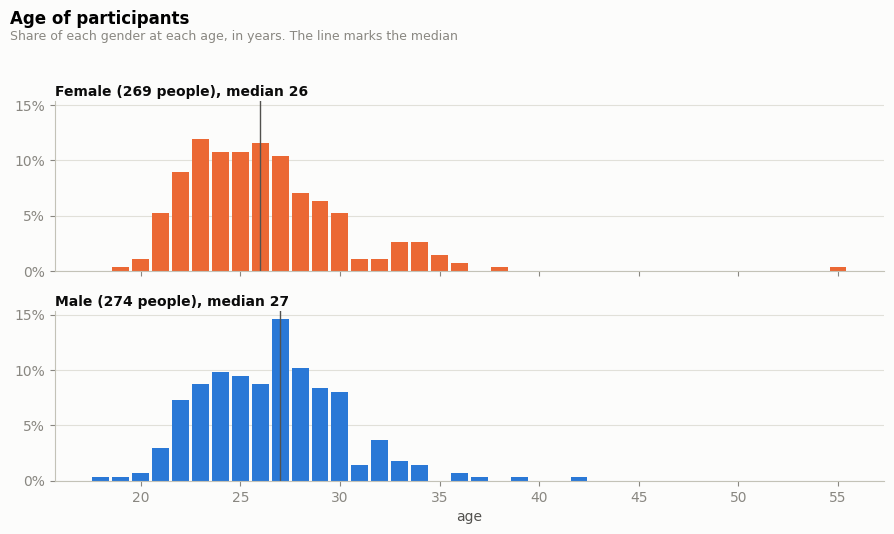

In [25]:
gender_histograms({g: people.loc[people["gender"] == g, "age"] for g in ("female", "male")},
                  bins=np.arange(17.5, people["age"].max() + 1.5),
                  title="Age of participants", subtitle="Share of each gender at each age, in years. The line marks the median",
                  xlabel="age")

#### What they look for in a partner

Question 1 at sign-up: everyone split 100 points across six attributes. After step 5 these are
shares that add up to 1, so each bar is the average share a gender gave the attribute.

Men put **attractiveness** far ahead of everything else (27% of their points). Women spread their
points more evenly, with **intelligence** first (21%), and they care more than men about
ambition (13% vs 9%) and shared interests.

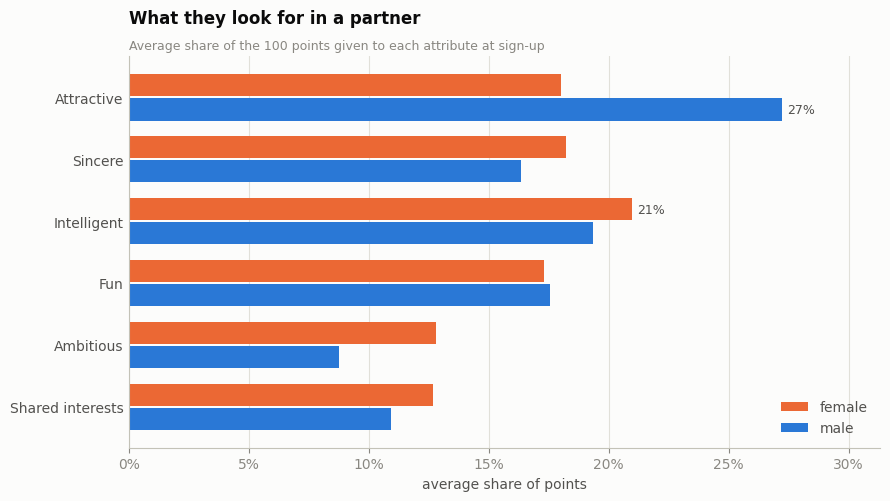

In [26]:
looking_for = people.groupby("gender")[PREFERENCES].mean().T
looking_for.index = PREFERENCE_NAMES
plot_by_gender(looking_for, "What they look for in a partner",
               "Average share of the 100 points given to each attribute at sign-up",
               xlabel="average share of points")

#### What they think the other sex wants

Question 2 asked the same thing about the opposite sex: *"What do you think the opposite sex looks
for in a date?"* Each panel puts one gender's own answer next to the other gender's guess. (Question
2 isn't on the `Person` nodes, so it comes from the raw file, scaled to shares the same way.)

Both genders overestimate how much the other side cares about looks. Women think men give 36% of
their points to attractiveness (men say 27%). Men think women give it 25% (women say 18%), and they
also underestimate how much women care about intelligence.

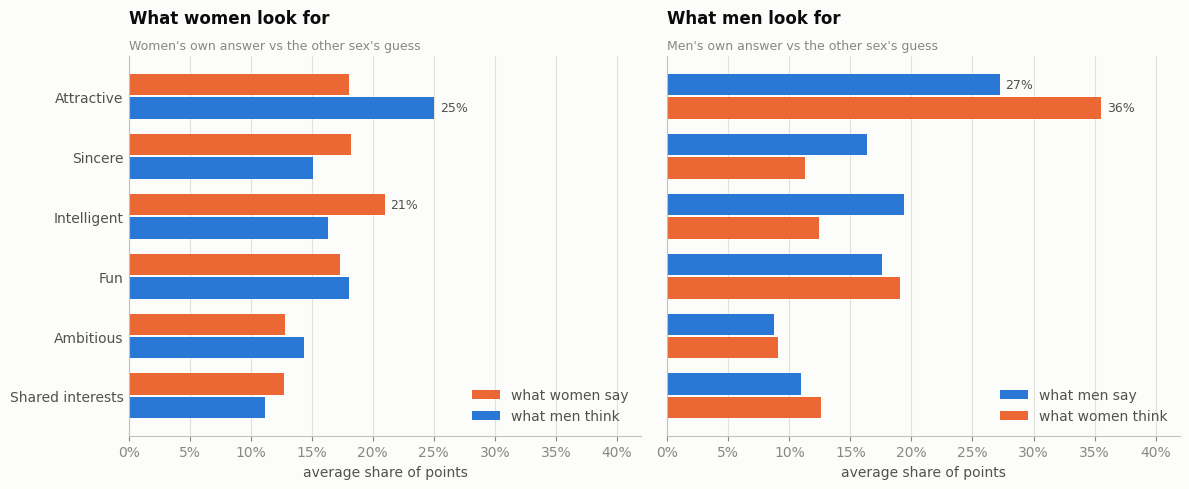

In [27]:
per_person = raw.dropna(subset=["pid"]).groupby("iid").first()
per_person["sex"] = per_person["gender"].map(GENDERS)
q2 = ["attr2_1", "sinc2_1", "intel2_1", "fun2_1", "amb2_1", "shar2_1"]
guess = per_person[q2].div(per_person[q2].sum(axis=1), axis=0).groupby(per_person["sex"]).mean().T
guess.index = PREFERENCE_NAMES
other = {"female": "male", "male": "female"}

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, gender in zip(axes, ("female", "male")):
    plural = {"female": "women", "male": "men"}
    hbars(ax, PREFERENCE_NAMES, invert=gender == "female", series=[
        (f"what {plural[gender]} say", looking_for[gender], GENDER_COLORS[gender]),
        (f"what {plural[other[gender]]} think", guess[other[gender]], GENDER_COLORS[other[gender]]),
    ])
    ax.set_xlim(0, 0.42)
    ax.set_xlabel("average share of points")
    titled(ax, f"What {plural[gender]} look for", f"{capitalised([plural[gender]])[0]}'s own answer vs the other sex's guess")
    ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

#### How they rate themselves

Question 3 at sign-up: *"How do you think you measure up?"*, each attribute on a 1-10 scale (there
is no self-rating for shared interests). People rate themselves high: almost every average is above 7,
with sincerity and intelligence the highest (about 8.1-8.5). Women rate themselves slightly higher
than men on everything except intelligence.

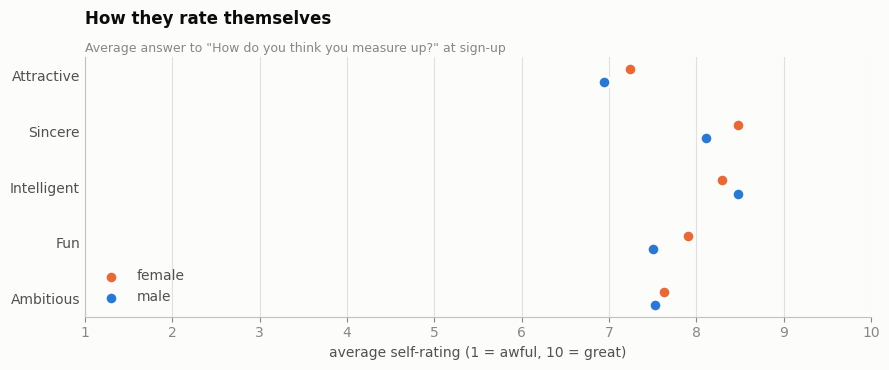

In [28]:
self_rating = people.groupby("gender")[SELF_RATINGS].mean().T
self_rating.index = PREFERENCE_NAMES[:5]

fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(self_rating))
for sign, gender in ((-1, "female"), (1, "male")):
    ax.scatter(self_rating[gender], y + sign * 0.12, s=80, color=GENDER_COLORS[gender],
               edgecolors=SURFACE, linewidths=2, zorder=3, label=gender)
ax.set_yticks(y, capitalised(self_rating.index))
ax.invert_yaxis()
ax.set_xlim(1, 10)
ax.set_xticks(range(1, 11))
ax.set_xlabel("average self-rating (1 = awful, 10 = great)")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0, labelcolor=INK_2)
titled(ax, "How they rate themselves", "Average answer to \"How do you think you measure up?\" at sign-up")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

#### Self-image vs how partners rated them

After every date, both people rated each other on the same five attributes (`attr_o`, `sinc_o`, ...
in the raw file: the ratings this person **received**). Averaging those over a person's dates gives
how they came across, which can be set against how they rated themselves.

Everyone rates themselves higher than their partners did, on every attribute, mostly by about
1 point. The biggest gap is for **fun** (women 7.9 self vs 6.5 from partners, men 7.5 vs 6.3), and
men also rate their own looks a full point above what their dates gave them (7.0 vs 5.9). The
smallest gap is men's ambition (7.5 vs 7.0). (These
ratings were given during the event, so they are only used here and never reach the model.)

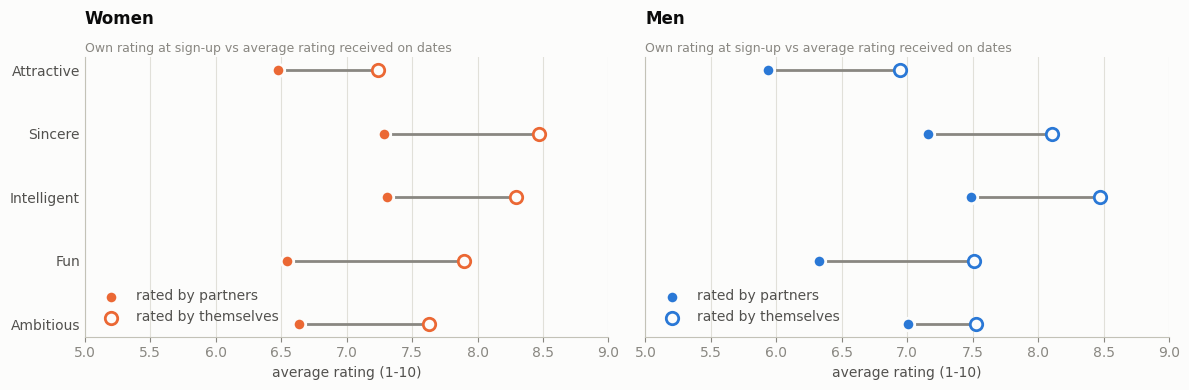

In [29]:
received_cols = ["attr_o", "sinc_o", "intel_o", "fun_o", "amb_o"]
dates = raw.dropna(subset=["pid"])
received = dates.groupby("iid")[received_cols].mean()
received = received.groupby(per_person["sex"]).mean().T
received.index = PREFERENCE_NAMES[:5]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, sharex=True)
y = np.arange(len(self_rating))
for ax, gender in zip(axes, ("female", "male")):
    color = GENDER_COLORS[gender]
    ax.hlines(y, received[gender], self_rating[gender], color=MUTED, linewidth=2, zorder=2)
    ax.scatter(received[gender], y, s=80, color=color, edgecolors=SURFACE, linewidths=2, zorder=3,
               label="rated by partners")
    ax.scatter(self_rating[gender], y, s=80, facecolors=SURFACE, edgecolors=color, linewidths=2, zorder=3,
               label="rated by themselves")
    ax.set_yticks(y, capitalised(self_rating.index))
    ax.set_xlim(5, 9)
    ax.set_xlabel("average rating (1-10)")
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0, labelcolor=INK_2)
    plural = {"female": "Women", "male": "Men"}[gender]
    titled(ax, plural, "Own rating at sign-up vs average rating received on dates")
    ax.legend(loc="lower left")
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

#### What actually makes them say yes

Stated preferences are one thing; decisions are another. For every date we know how this person
rated their partner on each attribute and whether they said yes (`dec`). The correlation between
the two shows which ratings actually go together with a yes.

For **both** genders, attractiveness is the strongest of the six (women 0.44, men 0.52), followed by
fun and shared interests. Intelligence and sincerity, which women put first when asked, matter much
less at the moment of decision (about 0.2). The overall "how much did you like this person"
rating (`like`) correlates even more strongly (0.48 and 0.54), but it isn't one of the six attributes.

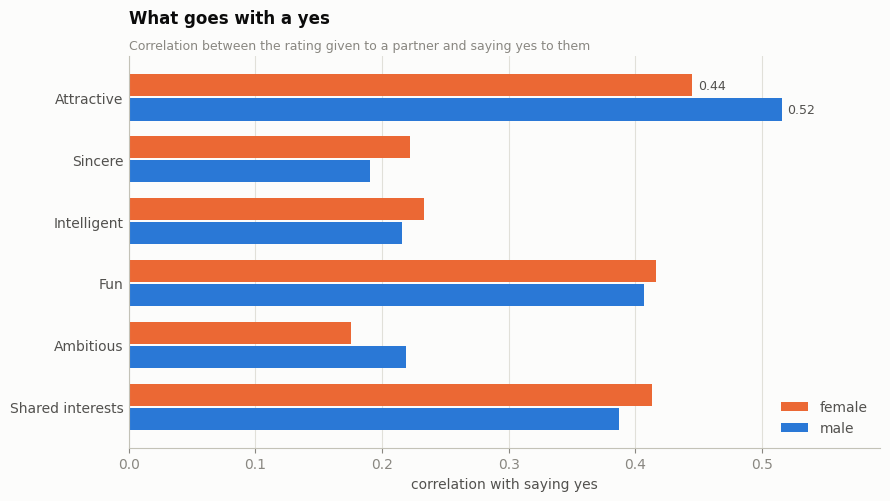

In [30]:
given = ["attr", "sinc", "intel", "fun", "amb", "shar"]
dates = dates.assign(sex=dates["gender"].map(GENDERS))
drives_yes = pd.DataFrame({sex: [d[c].corr(d["dec"]) for c in given] for sex, d in dates.groupby("sex")},
                          index=PREFERENCE_NAMES)
plot_by_gender(drives_yes, "What goes with a yes",
               "Correlation between the rating given to a partner and saying yes to them",
               xlabel="correlation with saying yes", fmt="{:.2f}", percent=False)

#### How picky are they

The share of their dates each person said yes to. Men are less picky: the median man said yes to
44% of his dates, the median woman to 37% (on average 48% vs 37%). Both distributions are wide:
22 women and 9 men said yes to nobody, and 6 women and 14 men said yes to everyone.

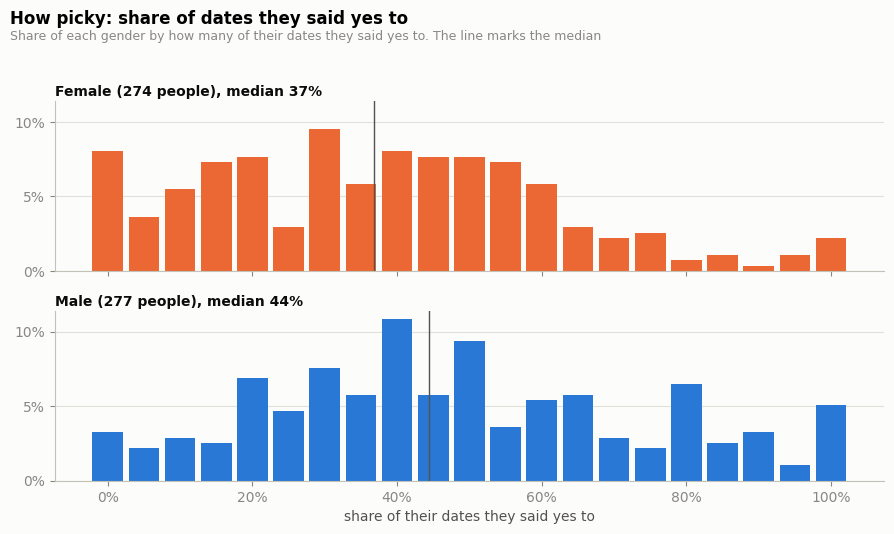

In [31]:
yes_rate = dates.groupby("iid")["dec"].mean()
gender_histograms({g: yes_rate[per_person["sex"] == g] for g in ("female", "male")},
                  bins=np.arange(-0.025, 1.05, 0.05), title="How picky: share of dates they said yes to",
                  subtitle="Share of each gender by how many of their dates they said yes to. The line marks the median",
                  xlabel="share of their dates they said yes to", median_fmt="{:.0%}", percent_x=True)